# RetailMind AI — Day 10: Seq2Seq Demand Forecasting with Attention

This standalone notebook uses a small LSTM encoder-decoder to forecast the next 7 days. It compares its one-day predictions with the Day 9 model and saves an attention heatmap.

## Before starting

Put Store Item Demand `train.csv` in `data/store-item-demand-forecasting/` or Rossmann `train.csv` in `data/rossmann-store-sales/`. Train Day 9 first; this notebook uses its saved model for a fair one-day comparison. It samples up to 24 time series and trains for at most 5 epochs to keep computation small.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA_DIR, MODEL_DIR, REPORT_DIR = ROOT / "data", ROOT / "models", ROOT / "reports"
MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)
LOOKBACK, HORIZON, MAX_SERIES = 28, 7, 24
BATCH_SIZE, EPOCHS, SEED = 256, 5, 42
tf.keras.utils.set_random_seed(SEED)

candidates = [DATA_DIR / "store-item-demand-forecasting" / "train.csv", DATA_DIR / "rossmann-store-sales" / "train.csv", DATA_DIR / "train.csv"]
csv_path = next((path for path in candidates if path.is_file()), None)
if csv_path is None: raise FileNotFoundError("Put train.csv in data/store-item-demand-forecasting/ or data/rossmann-store-sales/.")
data = pd.read_csv(csv_path)
columns = {str(name).strip().lower(): name for name in data.columns}
date_col, sales_col = columns.get("date"), columns.get("sales")
groups = [columns.get(name) for name in ("store", "store_id", "item", "item_id") if columns.get(name) is not None]
group_cols = list(dict.fromkeys(groups))
if date_col is None or sales_col is None or not any(str(c).lower() in ("store", "store_id") for c in group_cols): raise ValueError("CSV needs Date, Sales and Store columns; Item is optional.")
data[date_col] = pd.to_datetime(data[date_col], errors="coerce")
data[sales_col] = pd.to_numeric(data[sales_col], errors="coerce")
data = data.dropna(subset=[date_col, sales_col, *group_cols])
print("Dataset:", csv_path.name, "rows:", len(data))

## Prepare daily series and windows

For each series, the oldest 70% is used for training, the next 10% for validation, and the newest 20% for testing. Each input has 28 days; each target contains the following 7 days.

In [ ]:
series = []
for key, group in data.groupby(group_cols, sort=False):
    if not isinstance(key, tuple): key = (key,)
    daily = group.set_index(date_col)[sales_col].resample("D").sum()
    dates = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
    values = daily.reindex(dates, fill_value=0).to_numpy(dtype="float32")
    train_end, valid_end = int(len(values) * .7), int(len(values) * .8)
    if train_end <= LOOKBACK + HORIZON or valid_end <= train_end + HORIZON or len(values) <= valid_end + HORIZON: continue
    mean, scale = float(values[:train_end].mean()), float(values[:train_end].std())
    if scale == 0: scale = 1.0
    series.append({"ids": dict(zip(group_cols, key)), "dates": dates, "values": values, "scaled": (values - mean) / scale, "mean": mean, "scale": scale, "train_end": train_end, "valid_end": valid_end})
if len(series) > MAX_SERIES:
    chosen = [round(i * (len(series) - 1) / (MAX_SERIES - 1)) for i in range(MAX_SERIES)]
    series = [series[i] for i in chosen]
if not series: raise ValueError("No series are long enough for 28 input days and 7 forecast days.")
print("Time series used:", len(series))

def make_windows(part):
    x, y, info = [], [], []
    for one in series:
        if part == "train": start, end = LOOKBACK, one["train_end"] - HORIZON + 1
        elif part == "validation": start, end = one["train_end"], one["valid_end"] - HORIZON + 1
        else: start, end = one["valid_end"], len(one["values"]) - HORIZON + 1
        for target in range(start, end):
            x.append(one["scaled"][target-LOOKBACK:target])
            y.append(one["scaled"][target:target+HORIZON])
            info.append((one, target))
    if not x: raise ValueError("No windows for split: " + part)
    return np.asarray(x, dtype="float32")[..., None], np.asarray(y, dtype="float32")[..., None], info

x_train, y_train, _ = make_windows("train")
x_valid, y_valid, _ = make_windows("validation")
x_test, y_test, test_info = make_windows("test")
print("Train / validation / test windows:", len(x_train), len(x_valid), len(x_test))

## Train the Seq2Seq attention model

The encoder reads the history. The decoder creates seven outputs, and attention lets every output look back across the encoder's 28 daily steps.

In [ ]:
history_input = tf.keras.Input(shape=(LOOKBACK, 1))
encoded, hidden, cell = tf.keras.layers.LSTM(16, return_sequences=True, return_state=True)(history_input)
decoder_input = tf.keras.layers.RepeatVector(HORIZON)(hidden)
decoded = tf.keras.layers.LSTM(16, return_sequences=True)(decoder_input, initial_state=[hidden, cell])
attention_scores = tf.keras.layers.Dot(axes=[2, 2])([decoded, encoded])
attention_scores = tf.keras.layers.Softmax(axis=-1)(attention_scores)
context = tf.keras.layers.Dot(axes=[2, 1])([attention_scores, encoded])
joined = tf.keras.layers.Concatenate()([decoded, context])
forecast = tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(1))(joined)
model = tf.keras.Model(history_input, forecast)
attention_model = tf.keras.Model(history_input, attention_scores)
model.compile(optimizer="adam", loss="mse")
train_data = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(min(len(x_train), 10000), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
valid_data = tf.data.Dataset.from_tensor_slices((x_valid, y_valid)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
model.fit(train_data, validation_data=valid_data, epochs=EPOCHS, callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)], verbose=2)

## Compare, forecast, and visualize attention

The first forecast day is compared with Day 9 on exactly the same held-out inputs. The attention chart shows the history days used for each forecast horizon.

In [ ]:
day9_path = MODEL_DIR / "day9_demand_forecaster.keras"
if not day9_path.is_file(): raise FileNotFoundError("Train Day 9 first: " + str(day9_path))
day9_model = tf.keras.models.load_model(day9_path)
if day9_model.input_shape[1:] != (LOOKBACK, 1): raise ValueError("Day 9 model must accept 28 daily values.")
pred_scaled = model.predict(x_test, batch_size=BATCH_SIZE, verbose=0)[..., 0]
day9_scaled = day9_model.predict(x_test, batch_size=BATCH_SIZE, verbose=0).reshape(-1)
actual_all, pred_all, day9_errors, day10_errors, rows = [], [], [], [], []
for i, (one, target) in enumerate(test_info):
    actual = y_test[i, :, 0] * one["scale"] + one["mean"]
    predicted = np.maximum(0, pred_scaled[i] * one["scale"] + one["mean"])
    base = max(0, day9_scaled[i] * one["scale"] + one["mean"])
    day9_errors.append(abs(float(actual[0]) - float(base)))
    day10_errors.append(abs(float(actual[0]) - float(predicted[0])))
    actual_all.extend(actual.tolist())
    pred_all.extend(predicted.tolist())
    for step, value in enumerate(predicted):
        row = {"forecast_date": str(one["dates"][target+step].date()), "horizon_day": step+1, "actual_sales": float(actual[step]), "predicted_sales": float(value)}
        row.update(one["ids"])
        rows.append(row)
errors = np.asarray(actual_all) - np.asarray(pred_all)
metrics = pd.DataFrame([{"dataset": csv_path.parent.name, "series_count": len(series), "test_windows": len(test_info), "horizon_days": HORIZON, "day9_one_day_mae": np.mean(day9_errors), "day10_one_day_mae": np.mean(day10_errors), "day10_all_horizons_mae": np.mean(np.abs(errors)), "day10_all_horizons_rmse": np.sqrt(np.mean(errors**2))}])
display(metrics.round(3))
model.save(MODEL_DIR / "day10_seq2seq_attention_notebook.keras")
metrics.to_csv(REPORT_DIR / "day10_notebook_metrics.csv", index=False)
pd.DataFrame(rows).to_csv(REPORT_DIR / "day10_notebook_test_predictions.csv", index=False)

# Forecast the next 7 days for each selected series.
next_scaled = model.predict(np.asarray([s["scaled"][-LOOKBACK:] for s in series], dtype="float32")[..., None], verbose=0)[..., 0]
next_rows = []
for one, values in zip(series, next_scaled):
    for step, value in enumerate(values, 1):
        row = {"forecast_date": str((one["dates"][-1] + pd.Timedelta(days=step)).date()), "horizon_day": step, "forecast_sales": max(0, float(value*one["scale"]+one["mean"]))}
        row.update(one["ids"])
        next_rows.append(row)
pd.DataFrame(next_rows).to_csv(REPORT_DIR / "day10_notebook_next_7_days.csv", index=False)

weights = attention_model.predict(x_test[:1], verbose=0)[0]
weight_rows = [{"forecast_day": h+1, "history_day": d+1, "weight": float(w)} for h, row in enumerate(weights) for d, w in enumerate(row)]
pd.DataFrame(weight_rows).to_csv(REPORT_DIR / "day10_notebook_attention_weights.csv", index=False)
plt.figure(figsize=(11, 3))
plt.imshow(weights, aspect="auto", cmap="Reds")
plt.xlabel("History day (oldest to newest)")
plt.ylabel("Forecast day")
plt.colorbar(label="Attention weight")
plt.tight_layout()
plt.savefig(REPORT_DIR / "day10_notebook_attention.png", dpi=140)
plt.show()

## Saved files

- Model: `models/day10_seq2seq_attention_notebook.keras`
- Comparison and 7-day test errors: `reports/day10_notebook_metrics.csv`
- Held-out predictions: `reports/day10_notebook_test_predictions.csv`
- Next 7 days: `reports/day10_notebook_next_7_days.csv`
- Attention values and heatmap: `reports/day10_notebook_attention_weights.csv` and `reports/day10_notebook_attention.png`

## Saved output refresh

This cell displays the saved metrics and figures from `reports/` for this notebook. Training and generation cells are kept intact. Model-heavy workflows could not be rerun here because the required TensorFlow, PyTorch, or Transformers packages are unavailable; opt-in generation cells remain disabled.

Showing saved report artifacts for project day(s): [10]


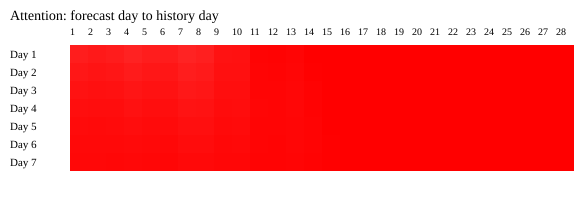


day10_attention_weights.csv


forecast_horizon_day,history_day,weight
1,1,0.031743
1,2,0.032331
1,3,0.031856
1,4,0.031029
1,5,0.031686
1,6,0.031919
1,7,0.030935
1,8,0.031451
1,9,0.033261
1,10,0.033362



day10_forecast_metrics.csv


dataset,series_count,test_windows,horizon_days,day9_one_day_mae,day10_one_day_mae,day10_all_horizons_mae,day10_all_horizons_rmse
store-item-demand-forecasting,24,8640,7,6.624972,9.105703,8.724121,11.573837



day10_next_7_days.csv


forecast_date,horizon_day,forecast_sales,store,item
2018-01-01,1,16.029821,1,1
2018-01-02,2,16.516489,1,1
2018-01-03,3,17.102592,1,1
2018-01-04,4,17.723398,1,1
2018-01-05,5,18.335890,1,1
2018-01-06,6,18.912548,1,1
2018-01-07,7,19.436998,1,1
2018-01-01,1,36.451607,3,3
2018-01-02,2,36.090042,3,3
2018-01-03,3,35.771549,3,3


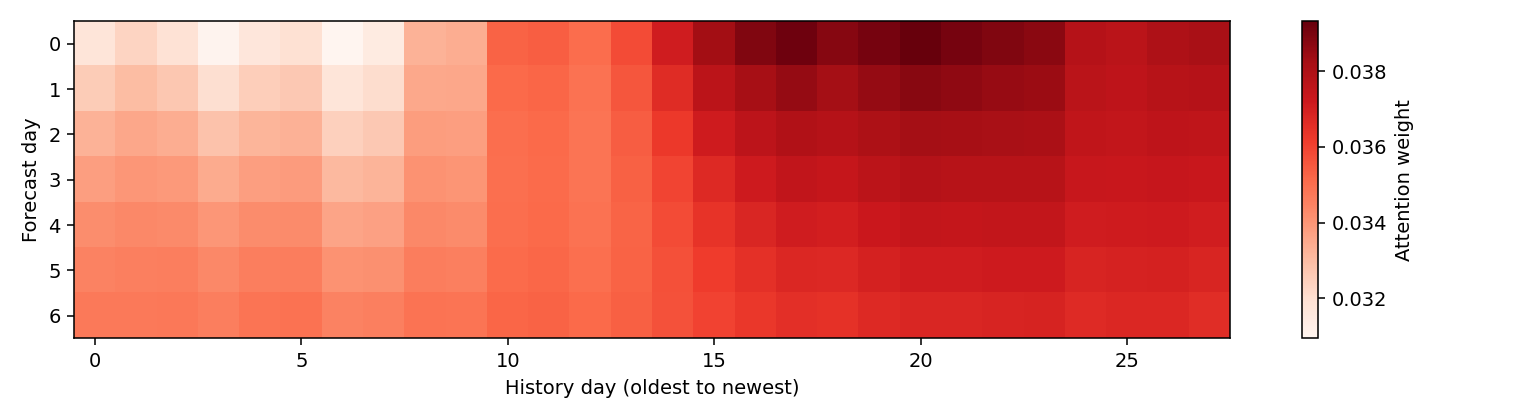


day10_notebook_attention_weights.csv


forecast_day,history_day,weight
1,1,0.031743
1,2,0.032331
1,3,0.031856
1,4,0.031029
1,5,0.031686
1,6,0.031919
1,7,0.030935
1,8,0.031451
1,9,0.033261
1,10,0.033362



day10_notebook_metrics.csv


dataset,series_count,test_windows,horizon_days,day9_one_day_mae,day10_one_day_mae,day10_all_horizons_mae,day10_all_horizons_rmse
store-item-demand-forecasting,24,8640,7,6.624972,9.105703,8.724121,11.573837



day10_notebook_next_7_days.csv


forecast_date,horizon_day,forecast_sales,store,item
2018-01-01,1,16.029821,1,1
2018-01-02,2,16.516489,1,1
2018-01-03,3,17.102592,1,1
2018-01-04,4,17.723398,1,1
2018-01-05,5,18.335890,1,1
2018-01-06,6,18.912548,1,1
2018-01-07,7,19.436998,1,1
2018-01-01,1,36.451607,3,3
2018-01-02,2,36.090042,3,3
2018-01-03,3,35.771549,3,3



day10_notebook_test_predictions.csv


forecast_date,horizon_day,actual_sales,predicted_sales,store,item
2016-12-31,1,14.0,17.002274,1,1
2017-01-01,2,19.0,17.402784,1,1
2017-01-02,3,15.0,17.805161,1,1
2017-01-03,4,10.0,18.167656,1,1
2017-01-04,5,16.0,18.469362,1,1
2017-01-05,6,14.0,18.702108,1,1
2017-01-06,7,24.0,18.866138,1,1
2017-01-01,1,19.0,17.316257,1,1
2017-01-02,2,15.0,17.633047,1,1
2017-01-03,3,10.0,17.874075,1,1



day10_test_predictions.csv


forecast_date,horizon_day,actual_sales,predicted_sales,store,item
2016-12-31,1,14.0,17.002274,1,1
2017-01-01,2,19.0,17.402786,1,1
2017-01-02,3,15.0,17.805161,1,1
2017-01-03,4,10.0,18.167656,1,1
2017-01-04,5,16.0,18.469362,1,1
2017-01-05,6,14.0,18.702110,1,1
2017-01-06,7,24.0,18.866140,1,1
2017-01-01,1,19.0,17.316257,1,1
2017-01-02,2,15.0,17.633047,1,1
2017-01-03,3,10.0,17.874075,1,1


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, SVG, display

# Re-display the saved metrics and figures for this notebook's project day.
# Set ROOT to the repository root if the notebook is launched elsewhere.
ROOT = Path.cwd()
if ROOT.name == "notebooks": ROOT = ROOT.parent
REPORT_DIR = ROOT / "reports"
DAYS = [10]
print("Showing saved report artifacts for project day(s):", DAYS)
for day in DAYS:
    for path in sorted(REPORT_DIR.glob(f"day{day}*")):
        if path.is_dir():
            for image_path in sorted(path.rglob("*.png")):
                display(Image(filename=str(image_path)))
        elif path.suffix.lower() == ".csv":
            print("\n" + path.name)
            display(pd.read_csv(path, nrows=25))
        elif path.suffix.lower() == ".png":
            display(Image(filename=str(path)))
        elif path.suffix.lower() == ".svg":
            display(SVG(filename=str(path)))
